# DataExploration.ipynb

This file was created to explore the sample data provided by the client. It contains functionality for plotting several aspects of the data and other explorations.

# Library Imports

In [ ]:
# Importing dependencies
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize, CenteredNorm
import numpy as np
from os.path import join

from astropy.io import fits
from astropy.nddata import Cutout2D
from astropy.wcs import WCS
from astropy.coordinates import SkyCoord
from astropy.units import Quantity

# Plot formatting
cm = 0.3937008
mpl.rcParams["figure.dpi"] = 150
mpl.rcParams["figure.figsize"] = np.array((8*cm, 5*cm))
mpl.rcParams["lines.linewidth"] = 0.2
mpl.rcParams["font.size"] = 5
mpl.rcParams["font.family"] = "serif"
mpl.rcParams["errorbar.capthick"] = 0.2
mpl.rcParams["errorbar.capsize"] = 0.5
mpl.rcParams["lines.markersize"] = 0.1

# Directory of the data
DATADIR = "/home/brad/OneDrive/UniWork/Year4/DataIntensivePhysics/Repository/SampleData/"

# Dictionary containing all data files
dataDict = {
	  "NIRH": "EUC_MER_BGSUB-MOSAIC-NIR-H_TILE102159484-39CF67_20241024T214009.099906Z_00.00.fits", 
	  "NIRJ": "EUC_MER_BGSUB-MOSAIC-NIR-J_TILE102159484-C026DB_20241024T213141.416722Z_00.00.fits", 
	  "NIRY": "EUC_MER_BGSUB-MOSAIC-NIR-Y_TILE102159484-A9CCA7_20241024T221227.957725Z_00.00.fits", 
	   "VIS": "EUC_MER_BGSUB-MOSAIC-VIS_TILE102159484-116033_20241025T015934.885975Z_00.00.fits", 
	   "CAT": "EUC_MER_FINAL-CAT_TILE102159484-EF6D85_20241026T003047.133877Z_00.00.fits", 
	"CUTOUT": "EUC_MER_FINAL-CUTOUTS-CAT_TILE102159484-73BCF1_20241025T145359.184204Z_00.00.fits", 
	 "MORPH": "EUC_MER_FINAL-MORPH-CAT_TILE102159484-AE979F_20241026T003045.182961Z_00.00.fits", 
	  "GSED": "EUC_PHZ_GALAXYSED__20241120T003959.957136Z_00.00.fits",
	"PHZCAT": "EUC_PHZ_PHZCAT__20241120T003850.158262Z_00.00.fits", 
	  "SSED": "EUC_PHZ_STARSED__20241120T003936.665995Z_00.00.fits", 
	"SPELIN":"EUC_SPE_WIDE-CAT-LIN-102159484_N_20241110T054343.637093Z_00.00.fits", 
	"SPEMOD": "EUC_SPE_WIDE-CAT-MOD-102159484_N_20241110T054509.870865Z_00.00.fits", 
	  "SPEZ": "EUC_SPE_WIDE-CAT-Z-102159484_N_20241110T054253.801351Z_00.00.fits"
}

# Function Definitions

In [82]:
def CropImage(image, centre, height, width, wcs):
	"""
	Get a cutout from an input `image` at `centre` with dimensions `width*height`
	"""
	# Getting the centre and size of the cutout
	centre = SkyCoord(centre[0], centre[1], unit="deg")
	size = Quantity([height, width], unit="deg")

	return Cutout2D(image[0].data, centre, size, wcs=wcs)

def GetCutout(image, cutout, wcs):
	"""
	Get the cropped image from a cutout entry.
	"""
	return CropImage(image, (cutout[1], cutout[2]), cutout[8]-cutout[4], cutout[3]-cutout[5], wcs)

def ShowCutout(image, cutout):
	"""
	Plot a given cutout from the image
	"""
	# Cropping the image to the cutout box
	croppedImg = GetCutout(image, cutout, WCS(image[0].header))

	# Plotting the cropped image
	fig, ax = plt.subplots(subplot_kw=dict(projection=croppedImg.wcs))

	# Plotting data
	ax.imshow(croppedImg.data, cmap="inferno", norm=LogNorm())
	ax.scatter(*np.flip(0.5*np.array(np.shape(croppedImg.data))), marker="+", s=50, lw=1, c="k")

	# Formatting
	ax.set_title(cutout[0])
	ax.set_xlabel("Right Ascension")
	ax.set_ylabel("Declination")
	
	return fig, ax

def GetSED(hdul, idx, EBounds=(4500, 10000), EStep=100):
	"""
	Get the SED for a row in the table
	"""
	# Creating empty arrays
	flux = np.empty(55)
	fluxErr = np.empty(55)
	E = np.empty(55)
	EErr = np.zeros(55)

	# Pulling the data
	for i, energy in enumerate(range(EBounds[0], EBounds[1], EStep)):
		flux[i] = hdul[1].data[idx][f"FLUX_{energy}_{energy+EStep}"]
		fluxErr[i] = hdul[1].data[idx][f"FLUXERR_{energy}_{energy+EStep}"]
		E[i] = energy + EStep/2

	return E, EErr, flux, fluxErr

def PlotSED(hdul, idx, EBounds=(4500, 10000), EStep=100, c="k", figax=None):
	"""
	Plot the SED for a given row in the input table
	"""
	# Creating a figure and axis object if unspecified
	if figax is None:
		fig, ax = plt.subplots()
	else:
		fig, ax = figax

	# Plotting the SED
	E, EErr, flux, fluxErr = GetSED(hdul, idx)
	ax.errorbar(
		E, flux, fluxErr, EErr, fmt=".", c=c
	)
	ax.step(E, flux, c=c, where="mid")

	# Axis formatting
	ax.set_xlabel("Wavelength ($\\AA$)")
	ax.set_ylabel("Flux")
	ax.set_title(hdul[1].data[idx][0])
	ax.set_xlim(EBounds)

	return fig, ax

def ShowAllCutouts(cutout, dataDict=dataDict, images=["VIS", "NIRH", "NIRJ", "NIRY"]):
	"""
	Show the input cutout for all 3 image bands
	"""
	# Getting the world coordinate system
	wcs = WCS(fits.open(join(DATADIR, f"{dataDict["VIS"]}"))[0].header)

	# Initialising the figure
	fig, axs = plt.subplots(4, 1, subplot_kw=dict(projection=wcs), sharex=True, figsize=(8*cm, 14*cm))

	for (i, image) in enumerate(images):

		# Reading the image
		with fits.open(join(DATADIR, f"{dataDict[image]}")) as hdul:
			# Getting the cutout from the image
			croppedImg = GetCutout(hdul, cutout, wcs).data
		
		# Plotting the image and a marker for the centre
		axs[i].imshow(croppedImg, cmap="plasma", norm=LogNorm())
		axs[i].scatter(*np.flip(0.5*np.array(np.shape(croppedImg))), marker="+", s=50, lw=1, c="k")

		# Labelling the image
		axs[i].annotate(
			image, xy=(1, 1), xycoords='axes fraction',
			xytext=(-5, -5), textcoords='offset points',
			ha='right', va='top', backgroundcolor="w"
		)

		# Axis formatting
		axs[i].set_xlabel("")
		axs[i].set_ylabel("Declination")
		axs[i].tick_params(axis="y", direction="in")
		axs[i].tick_params(axis="x", direction="in")
		if i != 3:
			axs[i].tick_params(axis="x", labelbottom=False)
	
	axs[3].set_xlabel("Right Ascension")

	fig.subplots_adjust(hspace=0)

	return fig, axs


def ShowTile(hdu, rebin=10, cmap="inferno"):
	"""
	Show the entire tile from an input image
	"""
	# Rebinning the image to save on RAM
	data = hdu[0].data[::rebin, ::rebin]

	# Plotting the image
	fig, ax = plt.subplots(subplot_kw=dict(projection=WCS(hdu[0].header)))
	ax.imshow(data, norm=LogNorm(), cmap=cmap)
	ax.set_xlabel("Right Ascension")
	ax.set_ylabel("Declination")

	return fig, ax


# Setup and Filehandling

In [97]:
# Image and cutout files
hdulCutouts = fits.open(join(DATADIR, f"{dataDict["CUTOUT"]}"))
# hdulImage  = fits.open(join(DATADIR, f"{DatadataDictDict[filt]}"))
hdulNIRH = fits.open(join(DATADIR, f"{dataDict["NIRH"]}"))
hdulNIRJ = fits.open(join(DATADIR, f"{dataDict["NIRJ"]}"))
hdulNIRY = fits.open(join(DATADIR, f"{dataDict["NIRY"]}"))
hdulVIS = fits.open(join(DATADIR, f"{dataDict["VIS"]}"))

# Morphology file
hdulMorph = fits.open(join(DATADIR, f"{dataDict["MORPH"]}"))

# SED files
hdulGSED = fits.open(join(DATADIR, f"{dataDict["GSED"]}"))
hdulSSED = fits.open(join(DATADIR, f"{dataDict["SSED"]}"))

hdulCAT = fits.open(join(DATADIR, f"{dataDict["CAT"]}"))
hdulLIN = fits.open(join(DATADIR, f"{dataDict["SPELIN"]}"))
hdulMOD = fits.open(join(DATADIR, f"{dataDict["SPEMOD"]}"))

# Showing the data

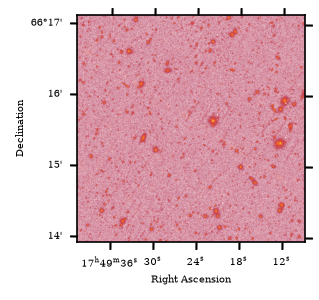

In [86]:
fig, ax = ShowTile(hdulVIS, rebin=10)

# Spectral Energy Distributions

PHZ_GAL_PROB    : 0.2050 (threshold 0.2205)
PHZ_STAR_PROB   : 0.8124 (threshold 0.5814)
PHZ_QSO_PROB    : 0.0139 (threshold 0.6687)
PHZ_GLOB_CL_PROB: 0.0000 (threshold 1.0000)


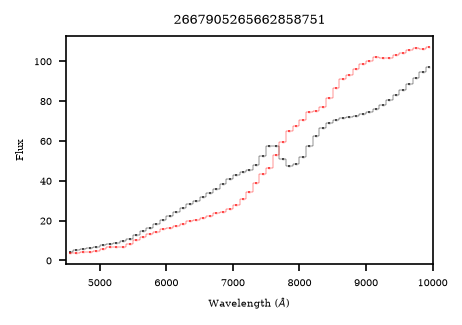

In [93]:
idx=np.random.choice(idxs)
columns = hdulGSED[1].columns

# Which object (row index) to use
gData = hdulGSED[1].data[idx]
sData = hdulSSED[1].data[idx]

for i in range(0, 8, 2):
	print(f"{columns[i-8].name:<16}: {sData[i-8]:.4f} (threshold {sData[i-7]:.4f})")

fig, ax = plt.subplots()

# Plotting the galactic SED
fig, ax = PlotSED(hdulGSED, idx, c="k", figax=(fig, ax))
fig, ax = PlotSED(hdulSSED, idx, c="r", figax=(fig, ax))

# Looking at the SED and the image

Object is a Galaxy


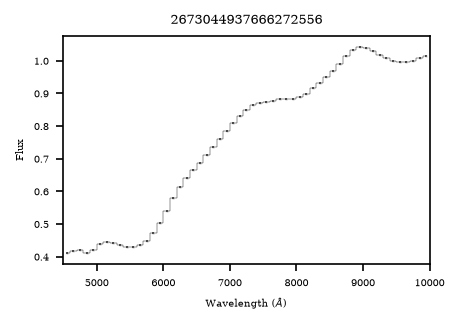

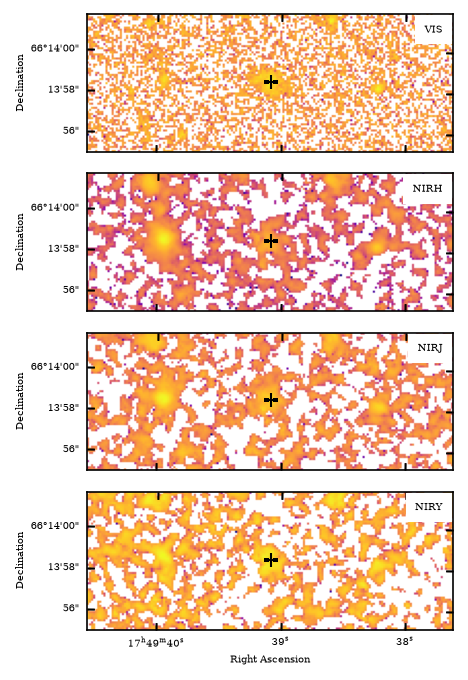

In [185]:
idx = np.random.choice(allIndices)

if np.invert(np.isnan(gFlux))[idx]:
    print("Object is a Galaxy")
    PlotSED(hdulGSED, idx)
elif np.invert(np.isnan(sFlux))[idx]:
    print("Object is a Star")
    PlotSED(hdulSSED, idx)
else: 
    print("Object Unknown")

fig, ax = ShowAllCutouts(hdulCutouts[1].data[idx])

# Interesting feature of the SED data

In [95]:
# Extracting the same column from the galaxy and star SED files
gData = hdulGSED[1].data
sData = hdulSSED[1].data

gFlux = gData["FLUX_4500_4600"]
sFlux = sData["FLUX_4500_4600"]
allIndices = np.arange(0, len(gFlux))

# Filtering to find what objects have data in both the galaxy and star SED dataset
condition = (np.invert(np.isnan(gFlux)) & np.invert(np.isnan(sFlux)))

# Counting the number of objects that have data for both a galaxy and star SED
nBoth = np.count_nonzero(condition)

# Taking the row indices 
idxs = allIndices[condition]

# Counting the number of objects that have each SED
nStars = len(sFlux) - np.count_nonzero(np.isnan(sFlux))
nGalaxies = len(gFlux) - np.count_nonzero(np.isnan(gFlux))

print(f"Of the {len(sFlux)} objects:")
print(f"    {round(100*nStars/len(sFlux), 1)}% ({nStars}) have a stellar SED")
print(f"    {round(100*nGalaxies/len(gFlux), 1)}% ({nGalaxies}) have a galactic SED")
print(f"    {nBoth} have both a stellar and galactic SED, at indices {idxs}")
print(f"    This is {round(100*nBoth/nStars, 1)}% of the stellar samples and {round(100*nBoth/nGalaxies, 1)}% of the galactic samples")

Of the 111422 objects:
    1.8% (1963) have a stellar SED
    52.0% (57919) have a galactic SED
    1963 have both a stellar and galactic SED, at indices [   74    80   147 ... 83830 83868 83894]
    This is 100.0% of the stellar samples and 3.4% of the galactic samples
